## PERTEMUAN 5 (Data Cleaning dan Transformation)
Nama    : Ilma Parma Sakia Daulay
Nim     : 241011400873
Kelas   : 05TPLP022

1. Loading Data

In [25]:
import pandas as pd
df = pd.read_csv("crop_yield.csv")
print(df.head())

  Region Soil_Type     Crop  Rainfall_mm  Temperature_Celsius  \
0   West     Sandy   Cotton   897.077239            27.676966   
1  South      Clay     Rice   992.673282            18.026142   
2  North      Loam   Barley   147.998025            29.794042   
3  North     Sandy  Soybean   986.866331            16.644190   
4  South      Silt    Wheat   730.379174            31.620687   

   Fertilizer_Used  Irrigation_Used Weather_Condition  Days_to_Harvest  \
0            False             True            Cloudy              122   
1             True             True             Rainy              140   
2            False            False             Sunny              106   
3            False             True             Rainy              146   
4             True             True            Cloudy              110   

   Yield_tons_per_hectare  
0                6.555816  
1                8.527341  
2                1.127443  
3                6.517573  
4                7.24825

2. Data Cleaning & Transformation

In [4]:
# Menampilkan ringkasan informasi dari dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 10 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   Region                  1000000 non-null  str    
 1   Soil_Type               1000000 non-null  str    
 2   Crop                    1000000 non-null  str    
 3   Rainfall_mm             1000000 non-null  float64
 4   Temperature_Celsius     1000000 non-null  float64
 5   Fertilizer_Used         1000000 non-null  bool   
 6   Irrigation_Used         1000000 non-null  bool   
 7   Weather_Condition       1000000 non-null  str    
 8   Days_to_Harvest         1000000 non-null  int64  
 9   Yield_tons_per_hectare  1000000 non-null  float64
dtypes: bool(2), float64(3), int64(1), str(4)
memory usage: 62.9 MB


In [5]:
# Menampilkan statistik deskriptif dari dataset
df.describe(include="all")

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
count,1000000,1000000,1000000,1000000.000000,1000000.000000,1000000,1000000,1000000,1000000.000000,1000000.000000
unique,4,6,6,NaN,NaN,2,2,3,NaN,NaN
top,North,Sandy,Maize,NaN,NaN,False,False,Sunny,NaN,NaN
freq,250173,167119,166824,NaN,NaN,500060,500509,333790,NaN,NaN
mean,NaN,NaN,NaN,549.981901,27.504965,NaN,NaN,NaN,104.495025,4.649472
std,NaN,NaN,NaN,259.851320,7.220608,NaN,NaN,NaN,25.953412,1.696572
min,NaN,NaN,NaN,100.000896,15.000034,NaN,NaN,NaN,60.000000,-1.147613
25%,NaN,NaN,NaN,324.891090,21.254502,NaN,NaN,NaN,82.000000,3.417637
50%,NaN,NaN,NaN,550.124061,27.507365,NaN,NaN,NaN,104.000000,4.651808
75%,NaN,NaN,NaN,774.738520,33.753267,NaN,NaN,NaN,127.000000,5.879200


2. (A) Memeriksa jumlah nilai yang hilang

2. (B) Mengatasi Missing Value

In [11]:

# Memisahkan kolom berdasarkan jumlah missing value
missing_values = df.isnull().sum()

less = missing_values[missing_values <= 0.75 * len(df)].index
over = missing_values[missing_values > 0.75 * len(df)].index

print("Kolom dengan missing value <= 75%:")
print(list(less))

print("Kolom dengan missing value > 75%:")
print(list(over))


Kolom dengan missing value <= 75%:
['Region', 'Soil_Type', 'Crop', 'Rainfall_mm', 'Temperature_Celsius', 'Fertilizer_Used', 'Irrigation_Used', 'Weather_Condition', 'Days_to_Harvest', 'Yield_tons_per_hectare']
Kolom dengan missing value > 75%:
[]


In [13]:

# Menghapus kolom dengan missing value lebih dari 75%
df = df.drop(columns=over).copy()

# Memisahkan kolom numerik dan kategorikal
numeric_features = df.select_dtypes(include=['number']).columns
categorical_features = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns

# Mengisi missing value numerik dengan median
df[numeric_features] = df[numeric_features].fillna(
    df[numeric_features].median()
)

# Mengisi missing value kategorikal dengan modus
for column in categorical_features:
    if df[column].isnull().any():
        df[column] = df[column].fillna(
            df[column].mode()[0]
        )

# Memeriksa kembali missing value
missing_values = df.isnull().sum()
missing_values[missing_values > 0]


C:\Users\rahma\AppData\Local\Temp\ipykernel_8156\566913746.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


Series([], dtype: int64)

2. (C) Mengatasi outlier

In [15]:

# Mengimpor library
import seaborn as sns
import matplotlib.pyplot as plt

# Memilih kolom numerik
numeric_features = df.select_dtypes(include=['number']).columns

# Memeriksa jumlah nilai hasil panen negatif
print(
    "Jumlah hasil panen negatif:",
    (df['Yield_tons_per_hectare'] < 0).sum()
)

# Menghapus nilai hasil panen yang tidak valid
df = df[df['Yield_tons_per_hectare'] >= 0].copy()

# Menghitung Q1, Q3, dan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

# Menentukan batas bawah dan batas atas
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Menghitung jumlah outlier per kolom
outlier_count = (
    (df[numeric_features] < lower_bound) |
    (df[numeric_features] > upper_bound)
).sum()

outlier_count[outlier_count > 0]


Jumlah hasil panen negatif: 231


Yield_tons_per_hectare    28
dtype: int64

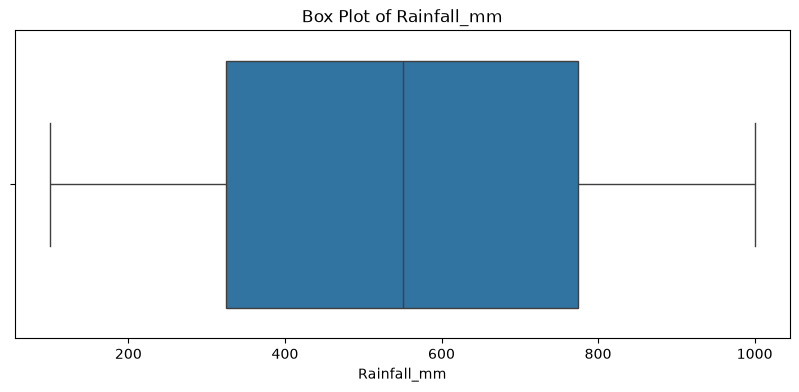

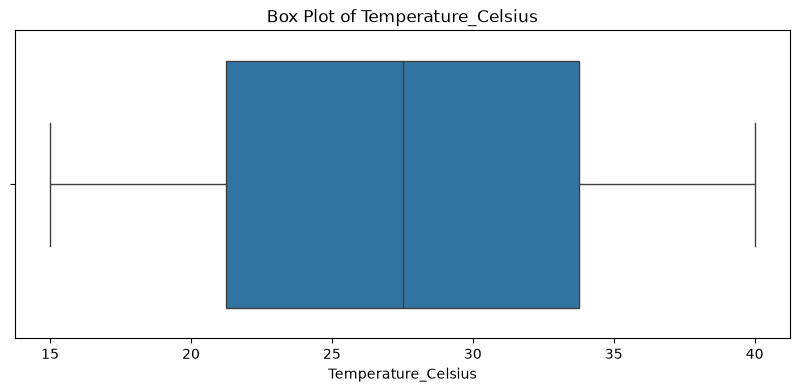

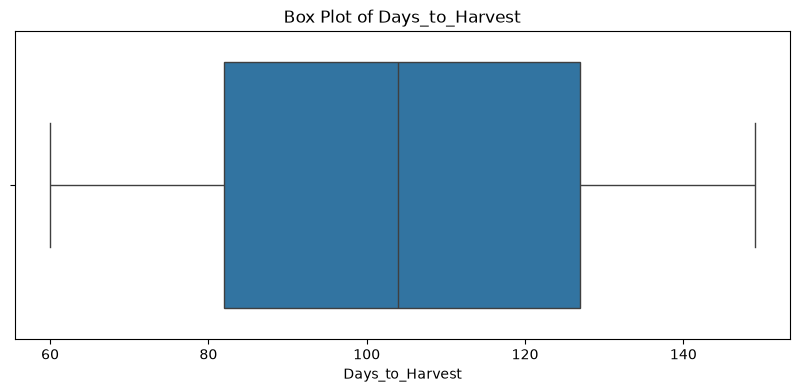

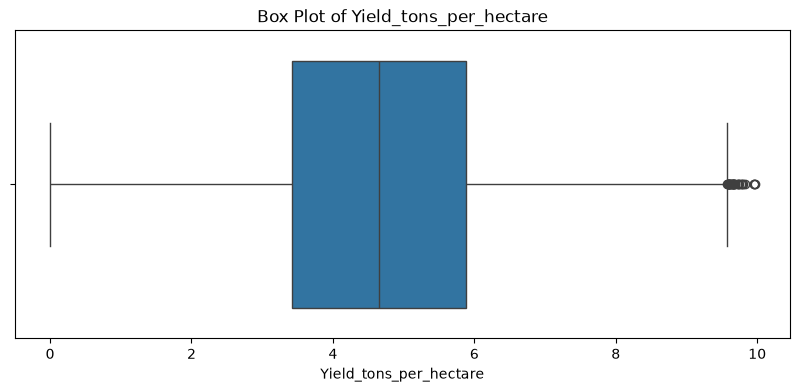

In [16]:

# Memeriksa outlier menggunakan boxplot
for feature in numeric_features:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()


In [17]:

# Menyaring baris yang tidak mengandung outlier
condition = ~(
    (df[numeric_features] < lower_bound) |
    (df[numeric_features] > upper_bound)
).any(axis=1)

# Menyimpan data tanpa outlier
df = df.loc[condition].copy()

# Memeriksa ukuran dataset setelah penanganan outlier
print("Ukuran dataset setelah penanganan outlier:", df.shape)


Ukuran dataset setelah penanganan outlier: (999741, 10)


3. Normalisasi dan Standarisasi

In [18]:

from sklearn.preprocessing import MinMaxScaler

# Memilih fitur numerik selain target prediksi
numeric_features = df.select_dtypes(
    include=['number']
).columns.drop('Yield_tons_per_hectare', errors='ignore')

# Menyimpan salinan data
df_normalized = df.copy()

# Melakukan normalisasi
normalizer = MinMaxScaler()
df_normalized[numeric_features] = normalizer.fit_transform(
    df_normalized[numeric_features]
)

# Menampilkan hasil normalisasi
df_normalized[numeric_features].head()


,Rainfall_mm,Temperature_Celsius,Days_to_Harvest
0,0.885643,0.507078,0.696629
1,0.991861,0.121045,0.898876
2,0.053330,0.591761,0.516854
3,0.985409,0.065766,0.966292
4,0.700422,0.664827,0.561798


In [19]:

from sklearn.preprocessing import StandardScaler

# Menyimpan salinan data
df_standardized = df.copy()

# Melakukan standarisasi
scaler = StandardScaler()
df_standardized[numeric_features] = scaler.fit_transform(
    df_standardized[numeric_features]
)

# Menampilkan hasil standarisasi
df_standardized[numeric_features].head()


,Rainfall_mm,Temperature_Celsius,Days_to_Harvest
0,1.335693,0.023691,0.674483
1,1.703656,-1.312907,1.368039
2,-1.547616,0.316897,0.057989
3,1.681304,-1.504301,1.599225
4,0.694050,0.569880,0.212113


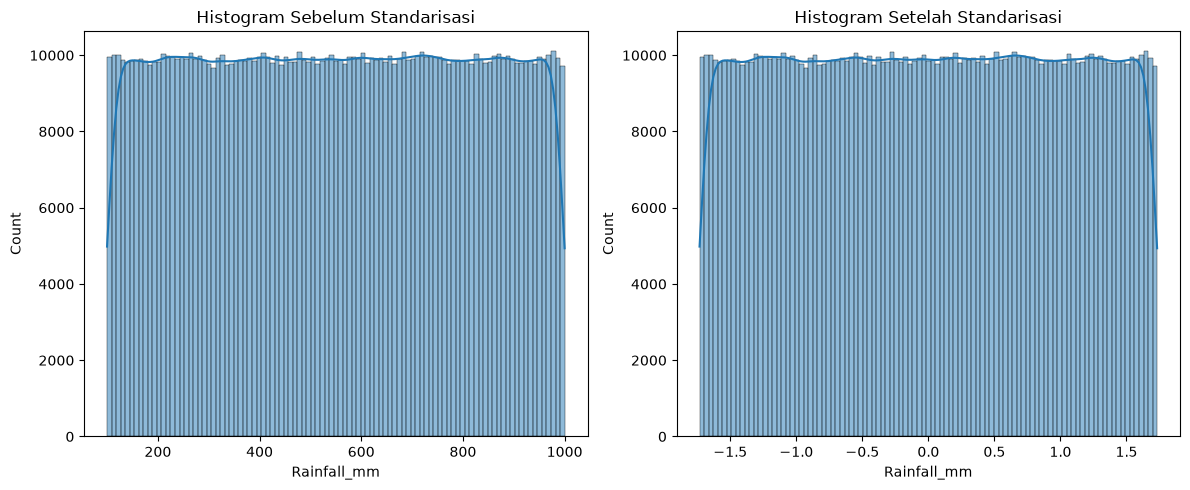

In [20]:

# Histogram sebelum dan sesudah standarisasi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Rainfall_mm'], kde=True)
plt.title('Histogram Sebelum Standarisasi')

plt.subplot(1, 2, 2)
sns.histplot(df_standardized['Rainfall_mm'], kde=True)
plt.title('Histogram Setelah Standarisasi')

plt.tight_layout()
plt.show()


3. (A) MENANANGANI DUPLIKASI DATA

In [21]:

# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Jumlah baris duplikat:")
print(duplicates.sum())

# Menghapus baris duplikat
df = df.drop_duplicates().copy()

# Memeriksa ukuran dataset
print("Ukuran dataset setelah menghapus duplikasi:", df.shape)


Jumlah baris duplikat:
0
Ukuran dataset setelah menghapus duplikasi: (999741, 10)


In [22]:

# Menentukan kolom kategorikal
categorical_features = [
    'Region',
    'Soil_Type',
    'Crop',
    'Weather_Condition'
]

# Mengubah kolom kategorikal menjadi tipe category
df[categorical_features] = df[categorical_features].astype('category')

# Mengubah kolom boolean menjadi numerik
df['Fertilizer_Used'] = df['Fertilizer_Used'].astype('int8')
df['Irrigation_Used'] = df['Irrigation_Used'].astype('int8')

# Memeriksa tipe data setelah konversi
df.dtypes


Region                    category
Soil_Type                 category
Crop                      category
Rainfall_mm                float64
Temperature_Celsius        float64
Fertilizer_Used               int8
Irrigation_Used               int8
Weather_Condition         category
Days_to_Harvest              int64
Yield_tons_per_hectare     float64
dtype: object

3 (B) ONE HOTE ENCODING

In [23]:

# Mengubah kolom kategorikal menjadi numerik
df_one_hot = pd.get_dummies(
    df,
    columns=categorical_features,
    dtype='int8'
)

# Menampilkan hasil encoding
df_one_hot.head()


,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Days_to_Harvest,Yield_tons_per_hectare,Region_East,Region_North,Region_South,Region_West,...,Soil_Type_Silt,Crop_Barley,Crop_Cotton,Crop_Maize,Crop_Rice,Crop_Soybean,Crop_Wheat,Weather_Condition_Cloudy,Weather_Condition_Rainy,Weather_Condition_Sunny
0,897.077239,27.676966,0,1,122,6.555816,0,0,0,1,...,0,0,1,0,0,0,0,1,0,0
1,992.673282,18.026142,1,1,140,8.527341,0,0,1,0,...,0,0,0,0,1,0,0,0,1,0
2,147.998025,29.794042,0,0,106,1.127443,0,1,0,0,...,0,1,0,0,0,0,0,0,0,1
3,986.866331,16.644190,0,1,146,6.517573,0,1,0,0,...,0,0,0,0,0,1,0,0,1,0
4,730.379174,31.620687,1,1,110,7.248251,0,0,1,0,...,1,0,0,0,0,0,1,1,0,0


## PERTEMUAN 6
Nama    : Ilma Parma Sakia Daulay
Nim     : 241011400873
Kelas   : 05TPLP022

1. Menampilkan data hasil Label Encoding

In [27]:

from sklearn.preprocessing import LabelEncoder

# Menentukan kolom kategorikal
categorical_features = [
    'Region',
    'Soil_Type',
    'Crop',
    'Weather_Condition'
]

# Membuat salinan dataset
df_lencoder = df.copy()

# Melakukan Label Encoding
label_encoders = {}

for col in categorical_features:
    label_encoder = LabelEncoder()
    df_lencoder[col] = label_encoder.fit_transform(
        df_lencoder[col].astype(str)
    )
    label_encoders[col] = label_encoder

# Menampilkan hasil
df_lencoder.head()


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,3,4,1,897.077239,27.676966,False,True,0,122,6.555816
1,2,1,3,992.673282,18.026142,True,True,1,140,8.527341
2,1,2,0,147.998025,29.794042,False,False,2,106,1.127443
3,1,4,4,986.866331,16.644190,False,True,1,146,6.517573
4,2,5,5,730.379174,31.620687,True,True,0,110,7.248251


2. Memeriksa missing value dan persentasenya

In [31]:

# Menghitung jumlah dan persentase missing value
missing_values = df_lencoder.isnull().sum()
missing_percentage = (
    missing_values / len(df_lencoder)
) * 100

# Membuat tabel missing value
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(
    by='Missing Values',
    ascending=False
)

# Menampilkan kolom yang memiliki missing value
missing_data[missing_data['Missing Values'] > 0]


,Missing Values,Percentage


3. Menampilkan histogram seluruh variabel

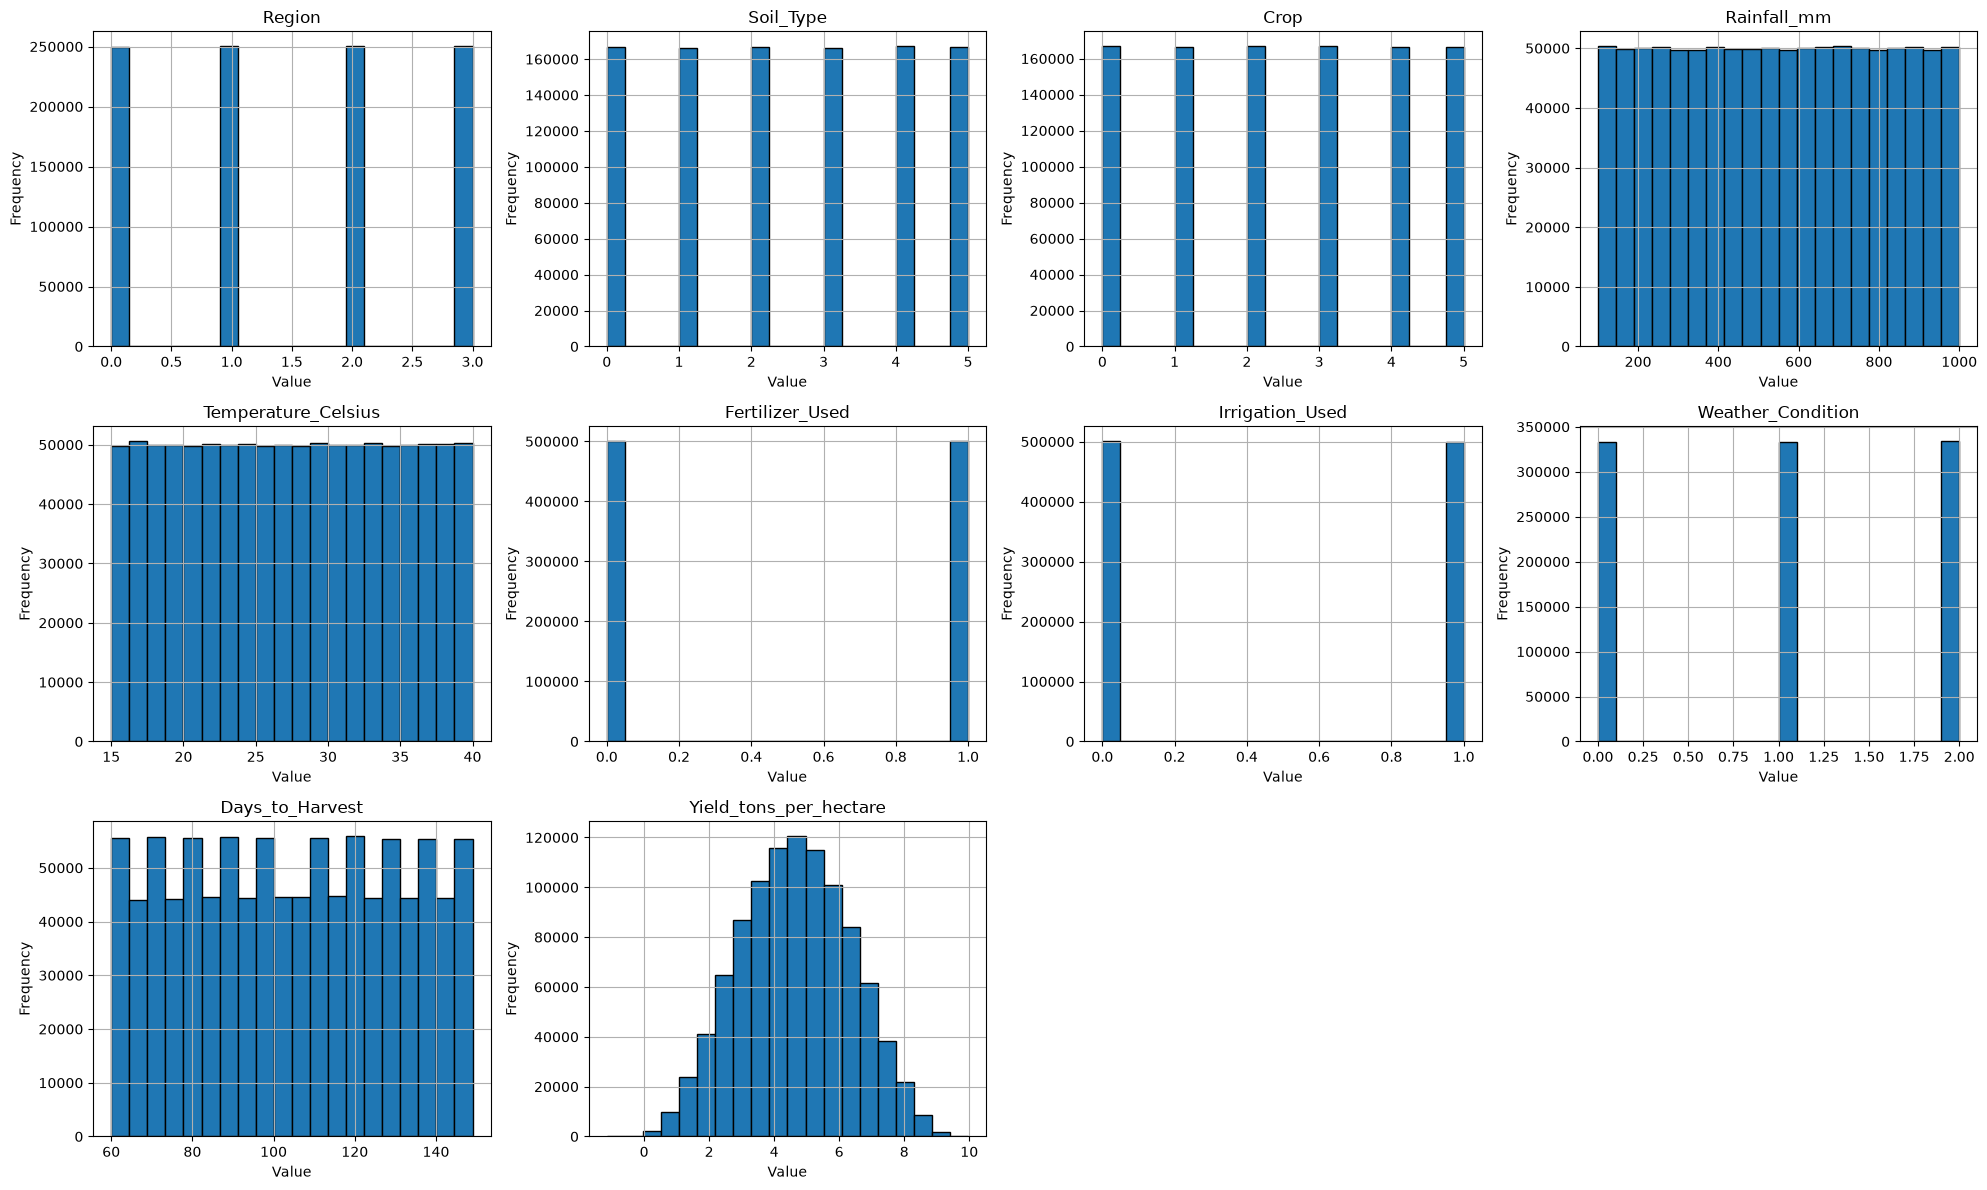

In [34]:

# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom subplot
n_cols = 4
n_rows = (num_vars + n_cols - 1) // n_cols

# Membuat subplot
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 4)
)

# Meratakan axes
axes = axes.flatten()

# Menampilkan histogram setiap variabel
for i, column in enumerate(df_lencoder.columns):
    data = df_lencoder[column]

    # Mengubah boolean menjadi angka sementara
    if data.dtype == 'bool':
        data = data.astype(int)

    data.hist(
        ax=axes[i],
        bins=20,
        edgecolor='black'
    )

    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai
for j in range(num_vars, len(axes)):
    fig.delaxes(axes[j])

# Merapikan tampilan
plt.tight_layout()
plt.show()


4. Visualisasi distribusi beberapa kolom

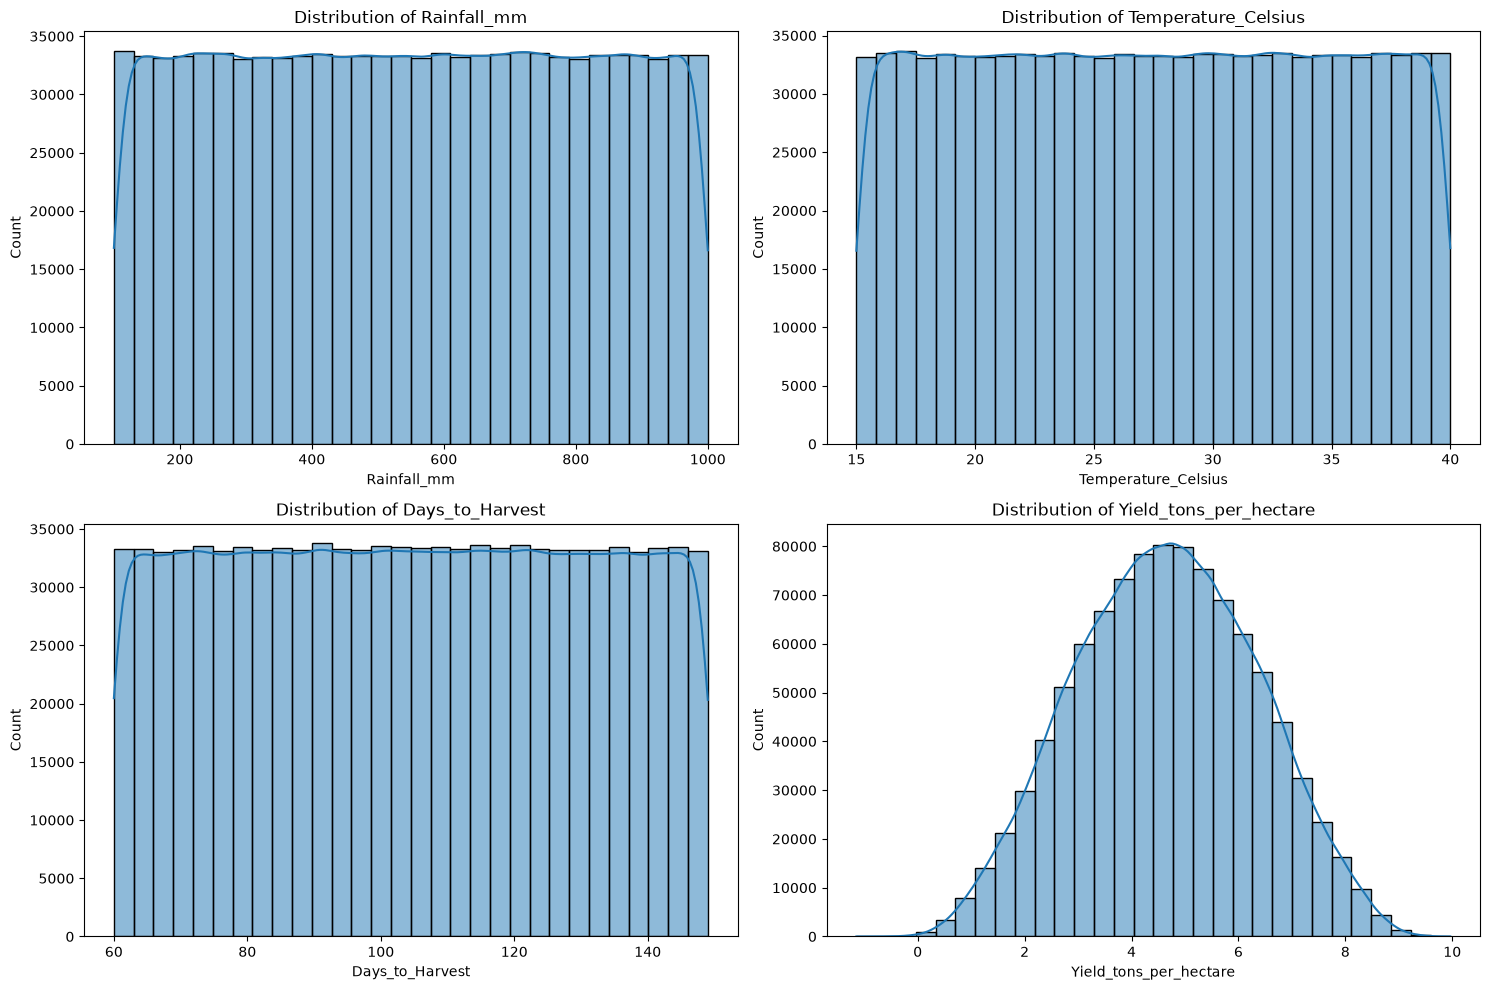

In [35]:

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = [
    'Rainfall_mm',
    'Temperature_Celsius',
    'Days_to_Harvest',
    'Yield_tons_per_hectare'
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(columns_to_plot):
    plt.subplot(2, 2, i + 1)
    sns.histplot(
        df_lencoder[column],
        kde=True,
        bins=30
    )
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()


5. Membuat matriks korelasi

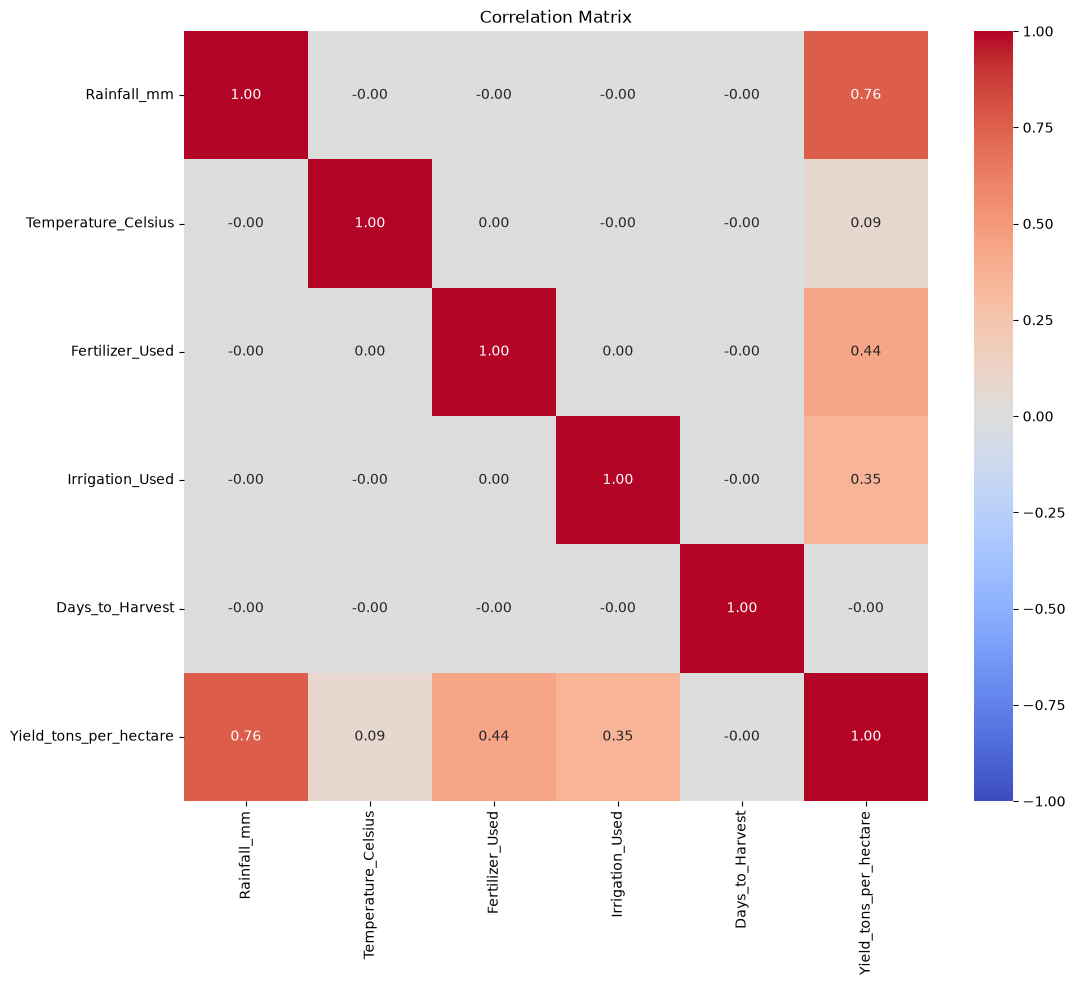

In [36]:

# Memilih kolom untuk analisis korelasi
correlation_columns = [
    'Rainfall_mm',
    'Temperature_Celsius',
    'Fertilizer_Used',
    'Irrigation_Used',
    'Days_to_Harvest',
    'Yield_tons_per_hectare'
]

# Membuat salinan data untuk korelasi
correlation_data = df_lencoder[correlation_columns].copy()

# Mengubah nilai boolean menjadi angka 0 dan 1
correlation_data['Fertilizer_Used'] = (
    correlation_data['Fertilizer_Used'].astype(int)
)

correlation_data['Irrigation_Used'] = (
    correlation_data['Irrigation_Used'].astype(int)
)

# Menghitung matriks korelasi
correlation_matrix = correlation_data.corr()

# Membuat heatmap korelasi
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()


6. Menganalisis korelasi terhadap hasil panen

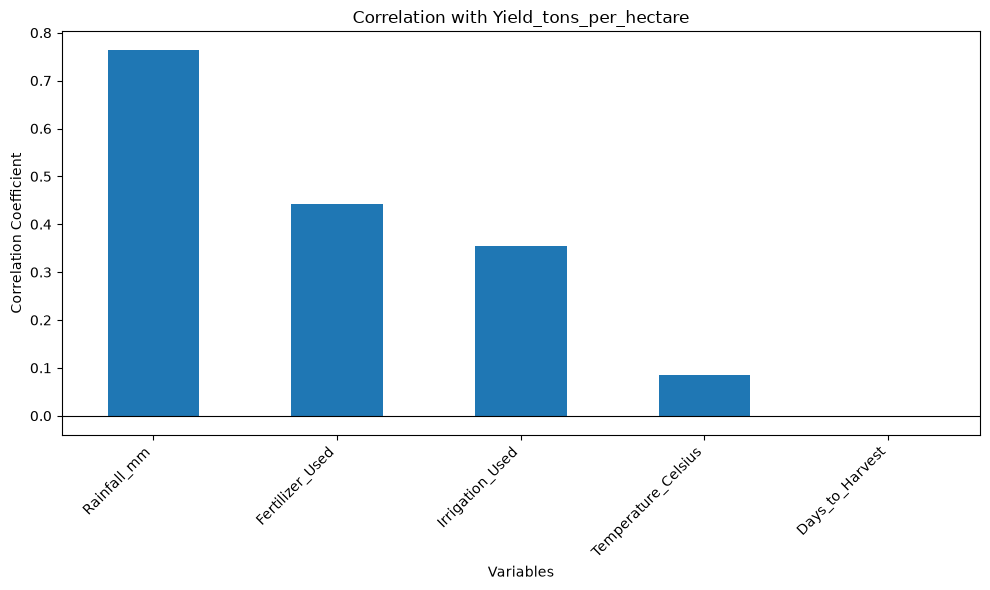

In [37]:

# Menghitung korelasi terhadap target hasil panen
target_corr = correlation_matrix['Yield_tons_per_hectare']

# Menghilangkan korelasi target dengan dirinya sendiri
target_corr = target_corr.drop('Yield_tons_per_hectare')

# Mengurutkan berdasarkan kekuatan korelasi absolut
target_corr_sorted = target_corr.loc[
    target_corr.abs().sort_values(ascending=False).index
]

# Membuat grafik korelasi
plt.figure(figsize=(10, 6))

target_corr_sorted.plot(kind='bar')

plt.title('Correlation with Yield_tons_per_hectare')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.axhline(y=0, color='black', linewidth=0.8)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


## PERTEMUAN 8 (DATA SPLITING)
Nama    : Ilma Parma Sakia Daulay
Nim     : 241011400873
Kelas   : 05TPLP022

1. Mengimpor library

In [38]:

# Mengimpor library untuk data splitting
from sklearn.model_selection import train_test_split


2. Memisahkan fitur (X) dan target (y)

In [39]:

# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(
    columns=['Yield_tons_per_hectare']
)

y = df_lencoder['Yield_tons_per_hectare']

# Menampilkan ukuran fitur dan target
print("Jumlah data fitur (X):", X.shape)
print("Jumlah data target (y):", y.shape)


Jumlah data fitur (X): (1000000, 9)
Jumlah data target (y): (1000000,)


3. Membagi dataset menjadi data training dan testing

In [40]:

# Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


4. Menghitung jumlah data hasil splitting

In [41]:

# Menghitung jumlah seluruh data
print("Jumlah data:", len(X))

# Menghitung jumlah data training
print("Jumlah data latih:", len(X_train))

# Menghitung jumlah data testing
print("Jumlah data test:", len(X_test))

# Memeriksa jumlah target training dan testing
print("Jumlah target latih:", len(y_train))
print("Jumlah target test:", len(y_test))


Jumlah data: 1000000
Jumlah data latih: 800000
Jumlah data test: 200000
Jumlah target latih: 800000
Jumlah target test: 200000


5. Memeriksa hasil pembagian data

In [42]:

# Menampilkan lima baris data training
print("Data Training:")
display(X_train.head())

# Menampilkan lima baris data testing
print("Data Testing:")
display(X_test.head())


Data Training:


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest
566853,1,4,4,887.383906,33.050569,True,True,0,79
382311,2,1,4,179.188444,24.699056,False,False,1,88
241519,2,5,5,649.310754,30.057577,False,False,0,120
719220,1,2,1,221.489100,19.508065,False,True,0,101
905718,0,3,3,737.016449,18.233438,True,False,1,88


Data Testing:


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest
987231,3,5,1,714.854403,23.875872,False,False,2,120
79954,1,0,1,860.604672,23.070897,False,False,1,78
567130,1,4,0,802.081954,24.020125,True,True,1,140
500891,3,0,1,203.616909,16.895211,False,True,2,96
55399,0,5,3,510.528102,18.402903,False,True,0,65
